<h1 align="center">RailSahayak AI: NLP-Based Analysis of Indian Railways Passenger Complaints</h1>

**Course:** M.Sc. Data Science
**Project domain:** Natural Language Processing  
**Case study:** Analysis and classification of passenger feedback about Indian Railways

### Group 1: Manjiri Apshinge (B061) & Tanvi Shinde (B064)

---
## Abstarct
Publicly shared passenger feedback contains useful information about railway service concerns, including delays, cleanliness, facilities, and complaint handling. However, the volume and informal nature of social-media text make systematic analysis difficult. This study applies Natural Language Processing (NLP) techniques to railway-related passenger tweets to identify complaints and classify the issue described. It compares statistical text representation, word embeddings, a recurrent neural network, and a transformer-based representation using a consistent evaluation framework. The results are used to assess predictive performance, computational cost, and the practical limitations of each approach.

---
## Aim
To compare different NLP techniques for identifying railway-related complaints and classifying the type of issue described in passenger tweets, while evaluating their effectiveness using appropriate performance metrics. The study also aims to analyse the strengths and limitations of traditional text representation methods, word embeddings, sequential deep learning models, and transformer-based models in extracting meaningful insights from real-world railway feedback.

---
## Objectives
1. Examine the dataset's structure, quality, class distribution, and text characteristics.
2. Preprocess passenger tweets for NLP modelling.
3. Build a TF-IDF-based baseline and compare it with Word2Vec, GloVe, LSTM, and DistilBERT-based approaches.
4. Evaluate complaint detection using accuracy, precision, recall, macro-F1, weighted-F1, and confusion matrices.
5. Investigate classification errors and assess the models' strengths, limitations, and computational requirements.
6. Explore issue-type classification for categories with sufficient data to support meaningful evaluation.

---
## Dataset
**Indian Railways Complaint Tweets** — publicly available on Hugging Face: [Dataset page](https://huggingface.co/datasets/faizmubeen/indian_railways_complaint_tweets).

The dataset contains railway-related tweets with labels for complaint status and issue type. Dataset size, columns, class distribution, missing values, and duplicate records are examined before modelling. The dataset source and license should be cited in the project report.

---
## Research questions
- How effectively can NLP models distinguish complaints from non-complaints?
- How do TF-IDF, Word2Vec, GloVe, LSTM, and a transformer-based approach compare on held-out data?
- Which evaluation measures best describe model performance when classes are imbalanced?
- What types of text are most likely to be misclassified, and what limitations affect the interpretation of results?

---
## Methodology overview
Dataset inspection → text cleaning → exploratory data analysis → stratified train-test split → model training → performance evaluation → model comparison → error analysis → conclusions.

**Computational approach:** DistilBERT is used as a lighter BERT-family model. Its pretrained weights are kept frozen and used to extract contextual embeddings, reducing computation compared with full transformer fine-tuning. The training sample and sequence length are bounded to keep the experiment practical.

---

## 1. Library setup

The following packages support data handling, visualisation, classical machine learning, word embeddings, recurrent neural networks, and transformer-based text representations.

In [1]:
%pip install -q datasets pandas numpy matplotlib seaborn scikit-learn gensim torch transformers tensorflow


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import re
import html
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

from datasets import load_dataset
from gensim.models import Word2Vec
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay
)
from sklearn.pipeline import Pipeline
from transformers import AutoTokenizer, AutoModel

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 140)

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())


PyTorch version: 2.11.0+cpu
CUDA available: False


---

## 2. Load the dataset
The dataset is publicly available and contains Indian Railways-related tweets. The dataset source and license are recorded for reproducibility.

In [3]:
dataset = load_dataset("faizmubeen/indian_railways_complaint_tweets")
print(dataset)
print("Available splits:", list(dataset.keys()))

split_name = list(dataset.keys())[0]
df = dataset[split_name].to_pandas()

print("Dataset shape:", df.shape)
print("Column names:", df.columns.tolist())
display(df.head())


DatasetDict({
    train: Dataset({
        features: ['Tweet', 'Label', 'Type'],
        num_rows: 4535
    })
})
Available splits: ['train']
Dataset shape: (4535, 3)
Column names: ['Tweet', 'Label', 'Type']


,Tweet,Label,Type
0,Balurghat is suffering from unnecessary late of the following train (13161) continuously. #IndianRailways is incessantly ignoring the s...,complaint,punctuality
1,My parents travelled by #garibrath train from Raipur to Lucknow after 3 years and were extremely disgusted by the state of #biotoilets\n...,complaint,cleanliness
2,#IndianRailways no response from IRCTC,complaint,facility
3,Stopped travelling in #IndianRailways way back... It stinks right from the Sec station all the way thru the boarding station with garbag...,complaint,cleanliness
4,"#IndianRailways 02563 BJU NDLS Running late by 4:30 hrs , bad service . I am in this train and I need to recieve my wife and Kid from Ni...",complaint,punctuality


---

## 3. Understand the data and check quality

In [4]:
print("Dataset information:")
df.info()

print("\nMissing values:")
display(df.isna().sum().to_frame("Missing values"))

print("\nDuplicate rows:", df.duplicated().sum())
print("\nFirst few rows:")
display(df.head(10))


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4535 entries, 0 to 4534
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Tweet   4535 non-null   object
 1   Label   4535 non-null   object
 2   Type    4535 non-null   object
dtypes: object(3)
memory usage: 106.4+ KB

Missing values:


,Missing values
Tweet,0
Label,0
Type,0



Duplicate rows: 31

First few rows:


,Tweet,Label,Type
0,Balurghat is suffering from unnecessary late of the following train (13161) continuously. #IndianRailways is incessantly ignoring the s...,complaint,punctuality
1,My parents travelled by #garibrath train from Raipur to Lucknow after 3 years and were extremely disgusted by the state of #biotoilets\n...,complaint,cleanliness
2,#IndianRailways no response from IRCTC,complaint,facility
3,Stopped travelling in #IndianRailways way back... It stinks right from the Sec station all the way thru the boarding station with garbag...,complaint,cleanliness
4,"#IndianRailways 02563 BJU NDLS Running late by 4:30 hrs , bad service . I am in this train and I need to recieve my wife and Kid from Ni...",complaint,punctuality
5,"@IRCTCofficial @AshwiniVaishnaw #IndianRailways being HQ of Eastern railway, Bhubaneswar (Odisha) has not received a single #VandeBhara...",complaint,miscellaneous
6,#UTS app wants me to be away at certain distance from railway station to book ticket\n\nIf I want to switch trains like from a sf expres...,complaint,ticket booking
7,"The violent #DrSanjayShrivastav at the service of #gangsters, hardcore #Misogynist ..Harassed a #epilepsy suffering #female employee to ...",complaint,miscellaneous
8,"Sir, this is the condition of ticket booking counter, Guwahati Railway Station.The working hour of evening start from 2:15 pm to 8:00 pm...",complaint,ticket booking
9,"Thinking of whether it is passenger train or expressÃ°Å¸â„¢â€ž....#Lalbagh 12607 (Nov25,2022) 15:30pm departure from Chn---Bang.... it...",complaint,punctuality


---

## 4. Standardise the column names
The text, complaint-label, and issue-type fields are identified from the dataset schema.

In [5]:
def find_column(columns, possible_names):
    names = {str(col).strip().lower(): col for col in columns}
    for name in possible_names:
        if name.lower() in names:
            return names[name.lower()]
    return None

text_column = find_column(df.columns, ["Tweet", "text", "tweet_text"])
label_column = find_column(df.columns, ["Label", "label", "complaint_label"])
type_column = find_column(df.columns, ["Type", "type", "issue_type", "category"])

if text_column is None or label_column is None or type_column is None:
    raise ValueError("Could not identify all required columns. Check the dataset column names printed above.")

df = df.rename(columns={
    text_column: "text",
    label_column: "complaint_label",
    type_column: "issue_type"
})
df = df[["text", "complaint_label", "issue_type"]].copy()

df["text"] = df["text"].astype(str).str.strip()
df["complaint_label"] = df["complaint_label"].astype(str).str.strip().str.lower()
df["issue_type"] = df["issue_type"].astype(str).str.strip().str.lower()

df = df.replace({"text": {"": np.nan, "nan": np.nan},
                 "complaint_label": {"": np.nan},
                 "issue_type": {"": np.nan}})
df = df.dropna(subset=["text", "complaint_label", "issue_type"])
df = df.drop_duplicates().reset_index(drop=True)

print("Cleaned dataset shape:", df.shape)
print("\nComplaint label counts:")
display(df["complaint_label"].value_counts().to_frame("Count"))
print("\nNumber of issue types:", df["issue_type"].nunique())
display(df["issue_type"].value_counts().head(15).to_frame("Count"))


Cleaned dataset shape: (4504, 3)

Complaint label counts:


,Count
complaint_label,
complaint,2595
non_complaint,1909



Number of issue types: 317


,Count
issue_type,
punctuality,898
others,401
cleanliness,276
miscellaneous,237
security,196
service,195
facility,193
informational,187
electrical equipment,170


---

## 5. Exploratory Data Analysis (EDA)

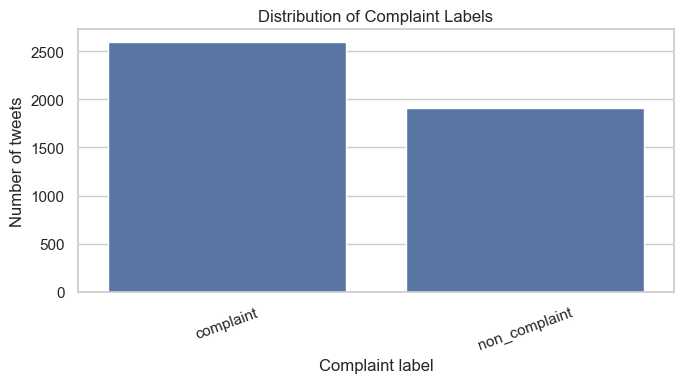

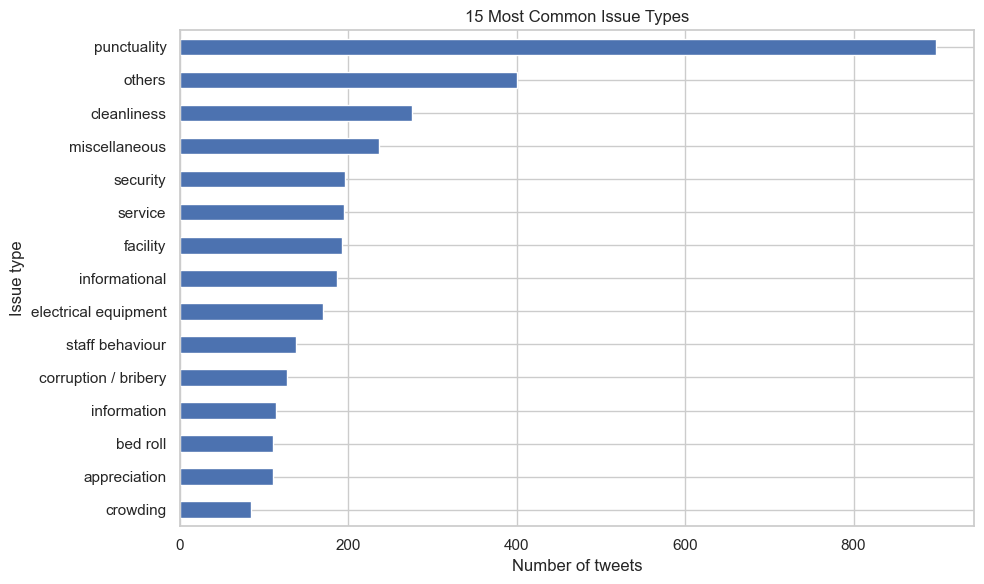

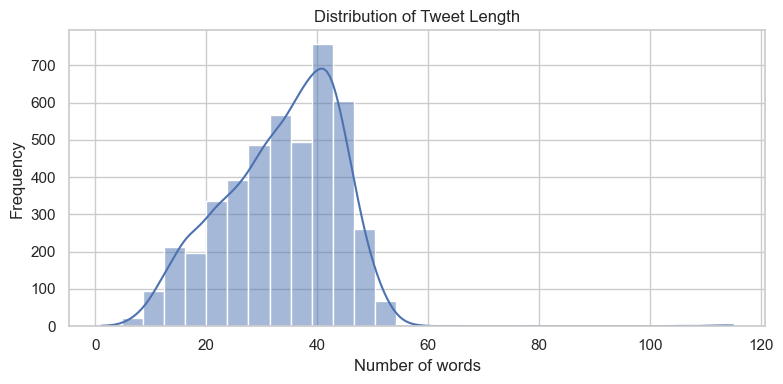

,Words per tweet
count,4504.000000
mean,33.615453
std,10.540953
min,1.000000
25%,26.000000
50%,35.000000
75%,42.000000
max,115.000000


In [6]:
# Chart 1: Distribution of complaint labels
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="complaint_label", order=df["complaint_label"].value_counts().index)
plt.title("Distribution of Complaint Labels")
plt.xlabel("Complaint label")
plt.ylabel("Number of tweets")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# Chart 2: Most common issue types
top_types = df["issue_type"].value_counts().head(15).sort_values()
plt.figure(figsize=(10, 6))
top_types.plot(kind="barh")
plt.title("15 Most Common Issue Types")
plt.xlabel("Number of tweets")
plt.ylabel("Issue type")
plt.tight_layout()
plt.show()

# Chart 3: Tweet length
df["word_count"] = df["text"].str.split().str.len()
plt.figure(figsize=(8, 4))
sns.histplot(df["word_count"], bins=30, kde=True)
plt.title("Distribution of Tweet Length")
plt.xlabel("Number of words")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

display(df["word_count"].describe().to_frame("Words per tweet"))


---

## 6. Clean the text
URLs, usernames, and unnecessary symbols are standardised. Negation words such as “not” are retained because they can change the meaning of a complaint.

In [7]:
def clean_text(text):
    text = html.unescape(str(text))
    text = re.sub(r"https?://\\S+|www\\.\\S+", " URL ", text)
    text = re.sub(r"@\\w+", " USER ", text)
    text = re.sub(r"#", "", text)
    text = re.sub(r"[^A-Za-z0-9'!?., ]+", " ", text)
    text = re.sub(r"\\s+", " ", text)
    return text.strip().lower()

df["clean_text"] = df["text"].apply(clean_text)
df = df[df["clean_text"].str.len() > 0].reset_index(drop=True)

display(df[["text", "clean_text", "complaint_label", "issue_type"]].head(8))


,text,clean_text,complaint_label,issue_type
0,Balurghat is suffering from unnecessary late of the following train (13161) continuously. #IndianRailways is incessantly ignoring the s...,balurghat is suffering from unnecessary late of the following train 13161 continuously. indianrailways is incessantly ignoring the su...,complaint,punctuality
1,My parents travelled by #garibrath train from Raipur to Lucknow after 3 years and were extremely disgusted by the state of #biotoilets\n...,my parents travelled by garibrath train from raipur to lucknow after 3 years and were extremely disgusted by the state of biotoilets we ...,complaint,cleanliness
2,#IndianRailways no response from IRCTC,indianrailways no response from irctc,complaint,facility
3,Stopped travelling in #IndianRailways way back... It stinks right from the Sec station all the way thru the boarding station with garbag...,stopped travelling in indianrailways way back... it stinks right from the sec station all the way thru the boarding station with garbage...,complaint,cleanliness
4,"#IndianRailways 02563 BJU NDLS Running late by 4:30 hrs , bad service . I am in this train and I need to recieve my wife and Kid from Ni...","indianrailways 02563 bju ndls running late by 4 30 hrs , bad service . i am in this train and i need to recieve my wife and kid from niz...",complaint,punctuality
5,"@IRCTCofficial @AshwiniVaishnaw #IndianRailways being HQ of Eastern railway, Bhubaneswar (Odisha) has not received a single #VandeBhara...","irctcofficial ashwinivaishnaw indianrailways being hq of eastern railway, bhubaneswar odisha has not received a single vandebharatex...",complaint,miscellaneous
6,#UTS app wants me to be away at certain distance from railway station to book ticket\n\nIf I want to switch trains like from a sf expres...,uts app wants me to be away at certain distance from railway station to book ticket if i want to switch trains like from a sf express to...,complaint,ticket booking
7,"The violent #DrSanjayShrivastav at the service of #gangsters, hardcore #Misogynist ..Harassed a #epilepsy suffering #female employee to ...","the violent drsanjayshrivastav at the service of gangsters, hardcore misogynist ..harassed a epilepsy suffering female employee to resig...",complaint,miscellaneous


---

## 7. Train-test split and evaluation function

The primary task is **complaint detection**. A stratified 80:20 train-test split preserves class proportions as closely as possible. The same held-out test set is used for the main model comparisons.

- **Accuracy:** overall proportion of correct predictions.
- **Precision:** how many predicted complaints are actually complaints.
- **Recall:** how many actual complaints the model identifies.
- **Macro-F1:** treats each class equally, useful when classes are imbalanced.
- **Weighted-F1:** accounts for class frequency.


In [8]:
X = df["clean_text"]
y = df["complaint_label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)

print("Training examples:", len(X_train))
print("Testing examples:", len(X_test))
print("\nTraining class proportions:")
display(y_train.value_counts(normalize=True).to_frame("Proportion"))

def evaluate_model(model_name, y_true, y_pred):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision (macro)": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "Macro-F1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "Weighted-F1": f1_score(y_true, y_pred, average="weighted", zero_division=0)
    }

results = []
model_predictions = {}


Training examples: 3603
Testing examples: 901

Training class proportions:


,Proportion
complaint_label,
complaint,0.576187
non_complaint,0.423813


---

## 8. Bag of Words (BoW) + Logistic Regression

Bag of Words (BoW) represents each tweet using word counts. Each vocabulary word becomes a feature, and each tweet is represented by the number of times each word occurs. Unlike TF-IDF, basic BoW does not down-weight words that occur in many documents.

This model uses the same training and test split as the other complaint-detection models.

The vectorizer is fitted on training text only and then applied to the test text using the learned vocabulary.

In [9]:
from IPython.display import display
def _display_report(y_true, y_pred, title):
    _report = classification_report(y_true, y_pred, output_dict=True, zero_division=0)
    _table = pd.DataFrame(_report).T.rename_axis("Class / average").reset_index()
    _table = _table.rename(columns={"precision":"Precision", "recall":"Recall",
                                    "f1-score":"F1-score", "support":"Support"})
    print(title)
    display(_table.style.format({"Precision":"{:.3f}", "Recall":"{:.3f}",
                                 "F1-score":"{:.3f}", "Support":"{:.0f}"}))

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score, f1_score

bow_model = Pipeline([
    ("bow", CountVectorizer(max_features=15000, ngram_range=(1, 2), min_df=2)),
    ("classifier", LogisticRegression(
        max_iter=1500, class_weight="balanced", random_state=SEED
    ))
])

bow_model.fit(X_train, y_train)
bow_predictions = bow_model.predict(X_test)

print("Bag of Words + Logistic Regression")
_display_report(y_test, bow_predictions, "Bag of Words + Logistic Regression — classification report")
print(f"Accuracy: {accuracy_score(y_test, bow_predictions):.3f}")
print(f"Macro-F1: {f1_score(y_test, bow_predictions, average='macro'):.3f}")

Bag of Words + Logistic Regression
Bag of Words + Logistic Regression — classification report


,Class / average,Precision,Recall,F1-score,Support
0,complaint,0.911,0.904,0.907,519
1,non_complaint,0.870,0.880,0.875,382
2,accuracy,0.893,0.893,0.893,1
3,macro avg,0.891,0.892,0.891,901
4,weighted avg,0.894,0.893,0.894,901


Accuracy: 0.893
Macro-F1: 0.891


### Interpretation

Compare accuracy and macro-F1 with the TF-IDF baseline. BoW uses raw counts, whereas TF-IDF adjusts feature weights according to how informative words are across the corpus. The `max_features` setting limits vocabulary size. Bigrams (`ngram_range=(1, 2)`) allow pairs of words such as `not working` to be represented together.

---

## 9. Model 1 — TF-IDF + Logistic Regression
TF-IDF represents tweets using term importance, while Logistic Regression learns the relationship between these features and the complaint label. This model provides the baseline for comparison.

Training and prediction time: 0.55 seconds
TF-IDF + Logistic Regression — classification report


,Class / average,Precision,Recall,F1-score,Support
0,complaint,0.904,0.925,0.914,519
1,non_complaint,0.895,0.866,0.880,382
2,accuracy,0.900,0.900,0.900,1
3,macro avg,0.899,0.896,0.897,901
4,weighted avg,0.900,0.900,0.900,901


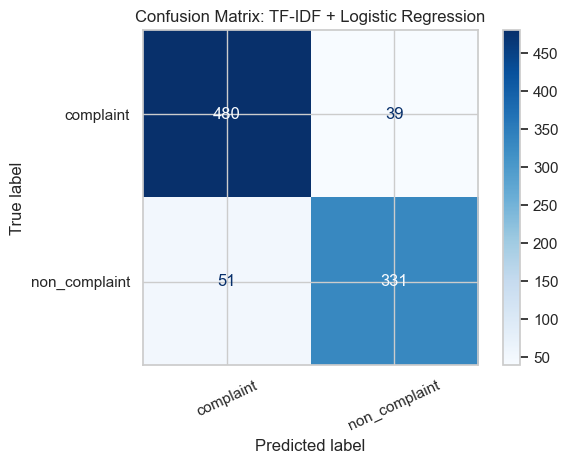

In [10]:
tfidf_model = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=30000, sublinear_tf=True)),
    ("classifier", LogisticRegression(max_iter=1500, class_weight="balanced", random_state=SEED))
])

start_time = time.time()
tfidf_model.fit(X_train, y_train)
tfidf_predictions = tfidf_model.predict(X_test)
print("Training and prediction time:", round(time.time() - start_time, 2), "seconds")

results.append(evaluate_model("TF-IDF + Logistic Regression", y_test, tfidf_predictions))
model_predictions["TF-IDF + Logistic Regression"] = tfidf_predictions

_display_report(y_test, tfidf_predictions, "TF-IDF + Logistic Regression — classification report")
ConfusionMatrixDisplay.from_predictions(y_test, tfidf_predictions, xticks_rotation=25, cmap="Blues")
plt.title("Confusion Matrix: TF-IDF + Logistic Regression")
plt.tight_layout()
plt.show()


---

## 10. Model 2 — Word2Vec + Logistic Regression
Word2Vec learns word representations from the training tweets. The word vectors are averaged to form a fixed-length tweet representation. This approach is computationally efficient, but it does not preserve word order.

In [11]:
train_tokens = [text.split() for text in X_train]
word2vec_model = Word2Vec(
    sentences=train_tokens, vector_size=100, window=5, min_count=2,
    workers=2, sg=1, epochs=20, seed=SEED
)

def average_word_vectors(texts, word_vectors, vector_size):
    document_vectors = []
    for text in texts:
        vectors = [word_vectors[word] for word in text.split() if word in word_vectors]
        if vectors:
            document_vectors.append(np.mean(vectors, axis=0))
        else:
            document_vectors.append(np.zeros(vector_size))
    return np.array(document_vectors)

X_train_w2v = average_word_vectors(X_train, word2vec_model.wv, 100)
X_test_w2v = average_word_vectors(X_test, word2vec_model.wv, 100)

w2v_classifier = LogisticRegression(max_iter=1500, class_weight="balanced", random_state=SEED)
start_time = time.time()
w2v_classifier.fit(X_train_w2v, y_train)
w2v_predictions = w2v_classifier.predict(X_test_w2v)
print("Training and prediction time:", round(time.time() - start_time, 2), "seconds")

results.append(evaluate_model("Word2Vec + Logistic Regression", y_test, w2v_predictions))
model_predictions["Word2Vec + Logistic Regression"] = w2v_predictions
_display_report(y_test, w2v_predictions, "Word2Vec + Logistic Regression — classification report")


Training and prediction time: 0.03 seconds
Word2Vec + Logistic Regression — classification report


,Class / average,Precision,Recall,F1-score,Support
0,complaint,0.891,0.913,0.902,519
1,non_complaint,0.878,0.848,0.863,382
2,accuracy,0.886,0.886,0.886,1
3,macro avg,0.885,0.881,0.882,901
4,weighted avg,0.885,0.886,0.885,901


---

## 11. Model 3 — GloVe + Logistic Regression
GloVe learns word representations from global word co-occurrence statistics. Pretrained Twitter GloVe vectors are used because they are designed for short, informal text. The pretrained vectors are downloaded during the first run.

In [12]:
import gensim.downloader as gensim_api

print("Downloading/loading pretrained GloVe Twitter vectors (first run may take a few minutes)...")
glove_model = gensim_api.load("glove-twitter-25")

def average_glove_vectors(texts, embeddings, vector_size=25):
    document_vectors = []
    for text in texts:
        vectors = [embeddings[word] for word in text.split() if word in embeddings]
        if vectors:
            document_vectors.append(np.mean(vectors, axis=0))
        else:
            document_vectors.append(np.zeros(vector_size))
    return np.array(document_vectors)

X_train_glove = average_glove_vectors(X_train, glove_model, 25)
X_test_glove = average_glove_vectors(X_test, glove_model, 25)

glove_classifier = LogisticRegression(max_iter=1500, class_weight="balanced", random_state=SEED)
start_time = time.time()
glove_classifier.fit(X_train_glove, y_train)
glove_predictions = glove_classifier.predict(X_test_glove)
print("Training and prediction time:", round(time.time() - start_time, 2), "seconds")

results.append(evaluate_model("GloVe Twitter + Logistic Regression", y_test, glove_predictions))
model_predictions["GloVe Twitter + Logistic Regression"] = glove_predictions
_display_report(y_test, glove_predictions, "GloVe Twitter + Logistic Regression — classification report")


Downloading/loading pretrained GloVe Twitter vectors (first run may take a few minutes)...
Training and prediction time: 0.02 seconds
GloVe Twitter + Logistic Regression — classification report


,Class / average,Precision,Recall,F1-score,Support
0,complaint,0.831,0.859,0.845,519
1,non_complaint,0.799,0.762,0.780,382
2,accuracy,0.818,0.818,0.818,1
3,macro avg,0.815,0.811,0.812,901
4,weighted avg,0.817,0.818,0.817,901


---

## 12. Model 4 — LSTM
LSTM is a recurrent neural network that processes tokens in sequence and can learn order-dependent patterns. A compact architecture is used to limit training time. The tokenizer is fitted only on the training text.

In [13]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from sklearn.preprocessing import LabelEncoder

MAX_WORDS = 10000
MAX_LENGTH = 80

tokenizer = Tokenizer(num_words=MAX_WORDS, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train)

X_train_seq = pad_sequences(tokenizer.texts_to_sequences(X_train), maxlen=MAX_LENGTH, padding="post", truncating="post")
X_test_seq = pad_sequences(tokenizer.texts_to_sequences(X_test), maxlen=MAX_LENGTH, padding="post", truncating="post")

label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

lstm_model = Sequential([
    Embedding(input_dim=min(MAX_WORDS, len(tokenizer.word_index) + 1), output_dim=64, mask_zero=True),
    LSTM(32),
    Dropout(0.3),
    Dense(len(label_encoder.classes_), activation="softmax")
])

lstm_model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
early_stop = __import__("tensorflow").keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=1, restore_best_weights=True
)

start_time = time.time()
lstm_model.fit(
    X_train_seq, y_train_encoded,
    validation_split=0.1, epochs=4, batch_size=32,
    callbacks=[early_stop], verbose=1
)
lstm_probabilities = lstm_model.predict(X_test_seq, verbose=0)
lstm_predictions = label_encoder.inverse_transform(np.argmax(lstm_probabilities, axis=1))
print("Training and prediction time:", round(time.time() - start_time, 2), "seconds")

results.append(evaluate_model("LSTM", y_test, lstm_predictions))
model_predictions["LSTM"] = lstm_predictions
_display_report(y_test, lstm_predictions, "LSTM — classification report")


Epoch 1/4
102/102 ━━━━━━━━━━━━━━━━━━━━ 6s 31ms/step - accuracy: 0.7884 - loss: 0.4698 - val_accuracy: 0.8837 - val_loss: 0.3076
Epoch 2/4
102/102 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step - accuracy: 0.9349 - loss: 0.1968 - val_accuracy: 0.9058 - val_loss: 0.2627
Epoch 3/4
102/102 ━━━━━━━━━━━━━━━━━━━━ 3s 27ms/step - accuracy: 0.9756 - loss: 0.0876 - val_accuracy: 0.8864 - val_loss: 0.3386
Training and prediction time: 12.57 seconds
LSTM — classification report


,Class / average,Precision,Recall,F1-score,Support
0,complaint,0.903,0.936,0.920,519
1,non_complaint,0.909,0.864,0.886,382
2,accuracy,0.906,0.906,0.906,1
3,macro avg,0.906,0.900,0.903,901
4,weighted avg,0.906,0.906,0.905,901


---

## 13. Model 5 — DistilBERT (efficient BERT-family model)

Full BERT fine-tuning can be computationally expensive. DistilBERT is a smaller transformer model. Its pretrained weights are **frozen** to extract contextual embeddings, after which Logistic Regression is trained on those embeddings.

This approach uses contextual representations from a transformer but does **not** fine-tune the transformer itself. It uses the same held-out test set as the other complaint-detection models. The number of training examples used to fit the classifier is capped to control computation; this limitation is considered when interpreting the results.

In [14]:
MODEL_NAME = "distilbert-base-uncased"
MAX_BERT_TRAIN = 1800
BATCH_SIZE = 16
MAX_BERT_LENGTH = 96

bert_tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
bert_encoder = AutoModel.from_pretrained(MODEL_NAME)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
bert_encoder.to(device)
bert_encoder.eval()

# Use a stratified subset of the training data for manageable computation.
bert_train = pd.DataFrame({"text": X_train, "label": y_train})
if len(bert_train) > MAX_BERT_TRAIN:
    bert_train, _ = train_test_split(
        bert_train, train_size=MAX_BERT_TRAIN, random_state=SEED,
        stratify=bert_train["label"]
    )
bert_X_train = bert_train["text"].reset_index(drop=True)
bert_y_train = bert_train["label"].reset_index(drop=True)

print("Device:", device)
print("DistilBERT training examples:", len(bert_X_train))
print("Test examples:", len(X_test))

def get_bert_embeddings(texts):
    all_embeddings = []
    texts = list(texts)
    for start in range(0, len(texts), BATCH_SIZE):
        batch_texts = texts[start:start + BATCH_SIZE]
        encoded = bert_tokenizer(
            batch_texts, padding=True, truncation=True,
            max_length=MAX_BERT_LENGTH, return_tensors="pt"
        )
        encoded = {key: value.to(device) for key, value in encoded.items()}
        with torch.no_grad():
            output = bert_encoder(**encoded)
            attention = encoded["attention_mask"].unsqueeze(-1)
            embeddings = (output.last_hidden_state * attention).sum(dim=1) / attention.sum(dim=1).clamp(min=1)
        all_embeddings.append(embeddings.cpu().numpy())
    return np.vstack(all_embeddings)

start_time = time.time()
bert_train_embeddings = get_bert_embeddings(bert_X_train)
bert_test_embeddings = get_bert_embeddings(X_test)
print("Embedding extraction time:", round(time.time() - start_time, 2), "seconds")

bert_classifier = LogisticRegression(max_iter=1500, class_weight="balanced", random_state=SEED)
bert_classifier.fit(bert_train_embeddings, bert_y_train)
bert_predictions = bert_classifier.predict(bert_test_embeddings)

results.append(evaluate_model("Frozen DistilBERT embeddings + Logistic Regression", y_test, bert_predictions))
model_predictions["Frozen DistilBERT embeddings + Logistic Regression"] = bert_predictions
_display_report(y_test, bert_predictions, "Frozen DistilBERT embeddings + Logistic Regression — classification report")


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Device: cpu
DistilBERT training examples: 1800
Test examples: 901
Embedding extraction time: 87.74 seconds
Frozen DistilBERT embeddings + Logistic Regression — classification report


,Class / average,Precision,Recall,F1-score,Support
0,complaint,0.926,0.915,0.921,519
1,non_complaint,0.887,0.901,0.894,382
2,accuracy,0.909,0.909,0.909,1
3,macro avg,0.906,0.908,0.907,901
4,weighted avg,0.909,0.909,0.909,901


---

## 14. Compare all model results
Macro-F1 is the primary comparison metric because it treats each class equally. The best model should be selected from the measured results, not assumed in advance.

,Model,Accuracy,Precision (macro),Recall (macro),Macro-F1,Weighted-F1
0,Frozen DistilBERT embeddings + Logistic Regression,0.909,0.906,0.908,0.907,0.909
1,LSTM,0.906,0.906,0.900,0.903,0.905
2,TF-IDF + Logistic Regression,0.900,0.899,0.896,0.897,0.900
3,Word2Vec + Logistic Regression,0.886,0.885,0.881,0.882,0.885
4,GloVe Twitter + Logistic Regression,0.818,0.815,0.811,0.812,0.817


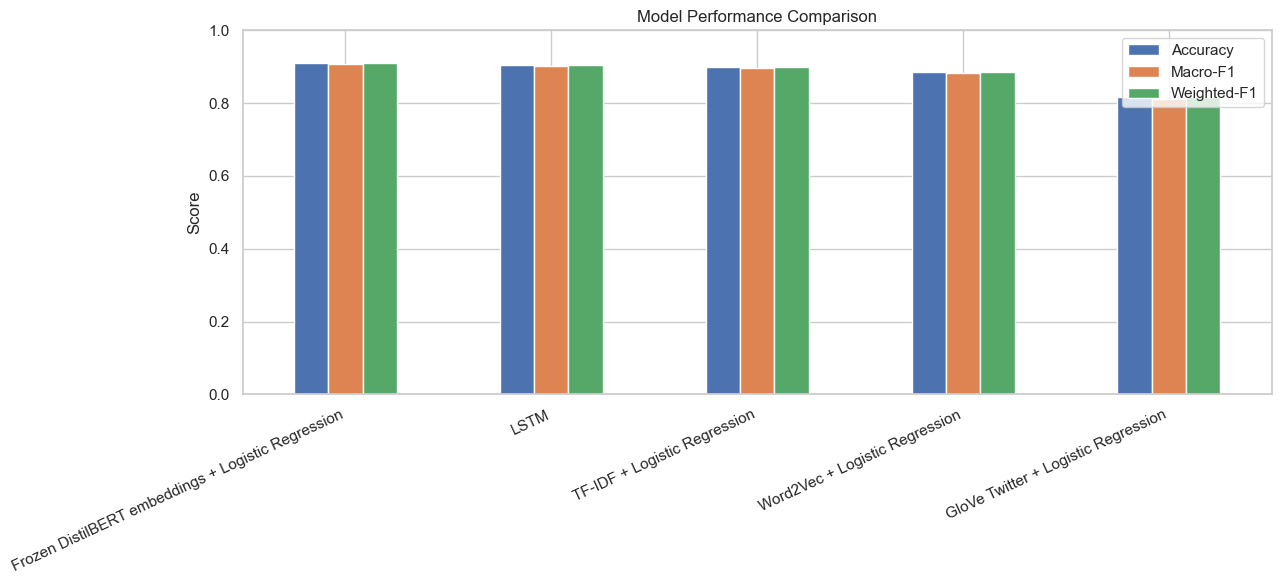

Best model based on Macro-F1: Frozen DistilBERT embeddings + Logistic Regression


In [15]:
results_df = pd.DataFrame(results).sort_values("Macro-F1", ascending=False).reset_index(drop=True)
display(results_df.style.format({
    "Accuracy": "{:.3f}",
    "Precision (macro)": "{:.3f}",
    "Recall (macro)": "{:.3f}",
    "Macro-F1": "{:.3f}",
    "Weighted-F1": "{:.3f}"
}))

plt.figure(figsize=(13, 6))
plot_data = results_df.set_index("Model")[["Accuracy", "Macro-F1", "Weighted-F1"]]
plot_data.plot(kind="bar", ax=plt.gca(), ylim=(0, 1))
plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

best_model_name = results_df.iloc[0]["Model"]
print("Best model based on Macro-F1:", best_model_name)


---

## 15. Confusion matrix for the best model

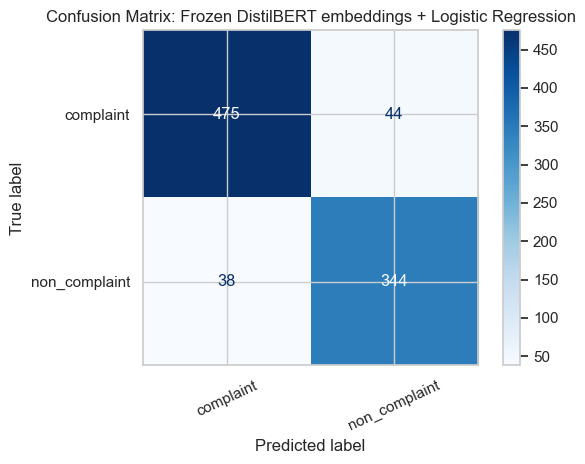

In [16]:
best_predictions = model_predictions[best_model_name]
ConfusionMatrixDisplay.from_predictions(
    y_test, best_predictions, xticks_rotation=25, cmap="Blues"
)
plt.title("Confusion Matrix: " + best_model_name)
plt.tight_layout()
plt.show()


---

## 16. Error analysis
Look at incorrect predictions from the baseline model. This helps explain what kinds of messages are difficult to classify.

In [17]:
error_analysis = pd.DataFrame({
    "Tweet": X_test.reset_index(drop=True),
    "Actual label": y_test.reset_index(drop=True),
    "Predicted label": pd.Series(model_predictions["TF-IDF + Logistic Regression"]).reset_index(drop=True)
})
errors = error_analysis[error_analysis["Actual label"] != error_analysis["Predicted label"]]
print("Number of baseline errors:", len(errors))
display(errors.head(20))


Number of baseline errors: 90


,Tweet,Actual label,Predicted label
0,we are disappointed as various youtubers are making videos on udaipur ahmedabad railway route to start operations in a very casual way w...,complaint,non_complaint
30,hope learns from supremecourtofindia is supreme joke now which is mocking the constitution of india for which it came into existenc...,non_complaint,complaint
34,westernrailways indianrailways railways train locomotives can stop at railway stations to take tea for the staff from the station. it do...,complaint,non_complaint
37,indian railways cancelled trains today list today october 6 howrah duranto express rescheduled how to claim full refund from irctc india...,complaint,non_complaint
59,"theupindex good news for passengers travelling to or from siddharthnagar district. take very long time but finally it happened, will als...",non_complaint,complaint
85,"drm dli railwayseva sir, this is such busy station in the capital of india with huge footfall of the passengers, also many important tr...",non_complaint,complaint
89,the halt has been deleted from the train root showing after get the confirmation msg. indianrailways https t.co kp5up1cudw,complaint,non_complaint
91,if agnipath could be implemented in indian defense forces. what would stop goi from implementing similar schemes on indianrailways or i...,non_complaint,complaint
114,what a wndrfl jrny from ludhiana to aligarh app.450 km with special weekly superfast train no.22432 ten hrs m 300 km chli hai train.waka...,non_complaint,complaint
115,traveling from valsad to mumbai just a journey of 300km think of who are travelling from bihar to maharashtra. making scheme and spendin...,non_complaint,complaint


---

## 17. Additional task — issue-type classification
Issue-type labels may be highly imbalanced, with many rare categories. To support more stable evaluation, this experiment retains categories with at least 25 examples and reports the number of retained records and classes. Issue-type classification is evaluated separately from complaint detection.

In [18]:
MINIMUM_TYPE_COUNT = 25
type_counts = df["issue_type"].value_counts()
common_types = type_counts[type_counts >= MINIMUM_TYPE_COUNT].index
type_df = df[df["issue_type"].isin(common_types)].copy()

print("Rows retained:", len(type_df), "out of", len(df))
print("Issue categories retained:", type_df["issue_type"].nunique())
display(type_df["issue_type"].value_counts().to_frame("Count"))

X_type_train, X_type_test, y_type_train, y_type_test = train_test_split(
    type_df["clean_text"], type_df["issue_type"],
    test_size=0.20, random_state=SEED, stratify=type_df["issue_type"]
)

type_model = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=30000)),
    ("classifier", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED))
])
type_model.fit(X_type_train, y_type_train)
type_predictions = type_model.predict(X_type_test)

print("Issue-type accuracy:", round(accuracy_score(y_type_test, type_predictions), 3))
print("Issue-type macro-F1:", round(f1_score(y_type_test, type_predictions, average="macro", zero_division=0), 3))
print("Issue-type weighted-F1:", round(f1_score(y_type_test, type_predictions, average="weighted", zero_division=0), 3))
print(classification_report(y_type_test, type_predictions, zero_division=0))


Rows retained: 3915 out of 4504
Issue categories retained: 24


,Count
issue_type,
punctuality,898
others,401
cleanliness,276
miscellaneous,237
security,196
service,195
facility,193
informational,187
electrical equipment,170


Issue-type accuracy: 0.443
Issue-type macro-F1: 0.363
Issue-type weighted-F1: 0.427
                            precision    recall  f1-score   support

              appreciation       0.14      0.23      0.17        22
                  bed roll       0.52      0.77      0.62        22
catering & vending service       0.33      0.36      0.34        14
               cleanliness       0.57      0.65      0.61        55
      corruption / bribery       0.33      0.31      0.32        26
                  crowding       0.42      0.76      0.54        17
      electrical equipment       0.54      0.41      0.47        34
                  facility       0.16      0.08      0.10        39
               information       0.15      0.30      0.20        23
             informational       0.35      0.45      0.40        38
               maintenance       0.62      0.38      0.48        13
        medical assistance       0.50      0.20      0.29         5
             miscellaneous     

---

## 18. Topic Modelling of Passenger Complaints using LDA

Latent Dirichlet Allocation (LDA) is an unsupervised topic-modelling method. Rather than predicting a predefined label for each tweet, LDA groups words that frequently occur together into topics. This analysis is used to explore recurring themes in passenger complaints.

The model is applied to the cleaned complaint tweets. Topics are interpreted using their top words and representative text. The coherence score provides an additional diagnostic, but does not by itself establish that a topic is meaningful.

A domain-specific stopword list is used to reduce the influence of common railway and social-media terms. The list should be reviewed because removing useful terms can affect the resulting topics.

In [19]:
# LDA topic modelling on complaint tweets (exploratory, unsupervised)
import re
from gensim import corpora
from gensim.models import LdaModel, CoherenceModel
from nltk.corpus import stopwords

import nltk

nltk.download("stopwords")


# Use complaint examples only so that the discovered topics focus on passenger issues.
complaint_texts = df.loc[
    df["complaint_label"].astype(str).str.lower().eq("complaint"), "clean_text"
].dropna().astype(str).tolist()

base_stopwords = set(stopwords.words("english"))
railway_stopwords = {
    "railway", "railways", "indianrailways", "train", "trains", "please",
    "kindly", "sir", "madam", "dear", "hello", "thanks", "thank", "http",
    "https", "url", "user"
}
topic_stopwords = base_stopwords | railway_stopwords

def preprocess_for_topics(text):
    tokens = re.findall(r"[a-z]{3,}", text.lower())
    return [token for token in tokens if token not in topic_stopwords]

topic_docs = [preprocess_for_topics(text) for text in complaint_texts]
topic_docs = [tokens for tokens in topic_docs if tokens]

topic_dictionary = corpora.Dictionary(topic_docs)
topic_dictionary.filter_extremes(no_below=5, no_above=0.60, keep_n=10000)
topic_corpus = [topic_dictionary.doc2bow(tokens) for tokens in topic_docs]

print("Complaint documents used:", len(topic_docs))
print("Vocabulary size after filtering:", len(topic_dictionary))
print("Documents with at least one retained token:", sum(bool(bow) for bow in topic_corpus))

if len(topic_dictionary) < 10 or not any(topic_corpus):
    print("Not enough vocabulary remains for reliable topic modelling. Review preprocessing/filters.")
else:
    lda_topic_model = LdaModel(
        corpus=topic_corpus,
        id2word=topic_dictionary,
        num_topics=5,
        random_state=SEED,
        passes=10,
        iterations=100,
        alpha="auto",
        eta="auto"
    )

    print("\nDiscovered topics (top words):")
    for topic_id, topic_words in lda_topic_model.print_topics(num_words=10):
        print(f"Topic {topic_id}: {topic_words}")

    topic_coherence = CoherenceModel(
        model=lda_topic_model,
        texts=topic_docs,
        dictionary=topic_dictionary,
        coherence="c_v"
    ).get_coherence()
    print(f"\nLDA coherence (c_v): {topic_coherence:.3f}")

[nltk_data] Downloading package stopwords to C:\Users\Manjiri
[nltk_data]     Apshinge\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Complaint documents used: 2595
Vocabulary size after filtering: 1413
Documents with at least one retained token: 2595

Discovered topics (top words):
Topic 0: 0.037*"coach" + 0.023*"travelling" + 0.019*"express" + 0.015*"traveling" + 0.014*"water" + 0.014*"number" + 0.014*"railminindia" + 0.014*"pnr" + 0.013*"ashwinivaishnaw" + 0.010*"seat"
Topic 1: 0.026*"irctc" + 0.019*"ashwinivaishnaw" + 0.017*"railminindia" + 0.014*"station" + 0.012*"food" + 0.010*"ticket" + 0.010*"take" + 0.008*"pnr" + 0.007*"one" + 0.007*"money"
Topic 2: 0.029*"ticket" + 0.028*"irctc" + 0.026*"railminindia" + 0.018*"ashwinivaishnaw" + 0.018*"irctcofficial" + 0.016*"booked" + 0.013*"tickets" + 0.013*"help" + 0.011*"got" + 0.011*"station"
Topic 3: 0.040*"late" + 0.029*"time" + 0.023*"hours" + 0.022*"running" + 0.022*"hrs" + 0.021*"railminindia" + 0.019*"ashwinivaishnaw" + 0.018*"station" + 0.016*"express" + 0.014*"indian"
Topic 4: 0.029*"railminindia" + 0.013*"irctcofficial" + 0.013*"ashwinivaishnaw" + 0.013*"centr

### Comparing the number of topics

Compare a small range of topic counts rather than assuming that five topics is optimal. Coherence is a useful diagnostic, not a definitive measure of topic quality. Inspect the top words for each candidate model to determine whether the topics are distinct and interpretable.

This experiment may take additional time. The comparison uses `topic_range = [3, 4, 5]`.

In [20]:
# Optional: compare topic counts using coherence
topic_range = [3, 4, 5]
topic_coherence_scores = []

if len(topic_dictionary) >= 10 and any(topic_corpus):
    for k in topic_range:
        candidate = LdaModel(
            corpus=topic_corpus,
            id2word=topic_dictionary,
            num_topics=k,
            random_state=SEED,
            passes=8,
            iterations=80,
            alpha="auto",
            eta="auto"
        )
        score = CoherenceModel(
            model=candidate,
            texts=topic_docs,
            dictionary=topic_dictionary,
            coherence="c_v"
        ).get_coherence()
        topic_coherence_scores.append(score)
        print(f"num_topics={k}: coherence={score:.3f}")

    if topic_coherence_scores:
        best_k = topic_range[topic_coherence_scores.index(max(topic_coherence_scores))]
        print(f"Highest coherence in this small search: {best_k} topics")
else:
    print("Topic-count comparison skipped because the filtered corpus is too small.")

num_topics=3: coherence=0.326
num_topics=4: coherence=0.299
num_topics=5: coherence=0.301
Highest coherence in this small search: 3 topics


### Interpretation of topics

- Name each topic only after reviewing its top words and representative tweets.
- If a topic contains generic words or several unrelated themes, revisit stopwords and dictionary filtering.
- Compare candidate topic counts using both coherence and human interpretability.
- Treat these topics as exploratory patterns in this dataset, not as verified categories for every Indian Railways complaint.

---

## 20. Project constraints and mitigation

The project was designed around two practical constraints. These constraints affect how the experiments should be interpreted and reproduced.

### Constraint 1: Limited computational resources

**Issue:** The notebook was executed in a CPU-only environment, with CUDA unavailable. Transformer-based representations can require substantial memory and computation, especially when processing the full dataset or fine-tuning a language model.

**Mitigation used:**
- DistilBERT was used as a feature extractor with its pretrained parameters frozen, followed by Logistic Regression. This is not full DistilBERT fine-tuning.
- DistilBERT embedding extraction was limited to a maximum of 1,800 training examples to keep the experiment manageable.
- The same held-out test set was used for the reported complaint-detection comparison.

**Effect on interpretation:** The DistilBERT result is based on a capped training subset, whereas the classical models and LSTM use the full training split. Therefore, the comparison is useful but not perfectly compute- or data-matched. The recorded runtime should also be considered alongside predictive performance.

### Constraint 2: Dataset size, label quality, and class imbalance

**Issue:** After text cleaning, the dataset contained 4,504 tweets. The complaint labels were not perfectly balanced, and issue-type classification included many infrequent categories. Social-media posts may also contain ambiguous wording, informal language, spelling variation, or imperfect labels.

**Mitigation used:**
- A stratified train-test split was used for complaint detection to preserve the class proportions.
- Macro-F1, precision, recall, accuracy, and weighted-F1 were reported rather than relying on accuracy alone.
- For the separate issue-type task, only categories with at least 25 examples were retained for modelling, leaving 3,915 examples across 24 categories.

**Effect on interpretation:** The issue-type experiment does not cover rare categories excluded by the frequency threshold. Its lower performance should be treated as evidence that fine-grained issue classification is more difficult than binary complaint detection, not as proof that the model can reliably classify every railway complaint. Since the dataset labels are supplied annotations, predictions should support human review rather than be treated as verified facts.

### Reproducibility note

The dataset is obtained from the public Hugging Face dataset page cited below. Before submission, verify the dataset card's stated provenance and license, and record the date on which the dataset was accessed. Public availability alone does not establish that the sample represents all Indian Railways passengers.


---

## 21. Results, discussion, and conclusion

### Complaint-detection results

The cleaned dataset contained **4,504 tweets**: **2,595 complaint** tweets and **1,909 non-complaint** tweets. A stratified split produced **3,603 training examples** and **901 test examples**.

| Model | Accuracy | Macro-precision | Macro-recall | Macro-F1 | Weighted-F1 |
|---|---:|---:|---:|---:|---:|
| Frozen DistilBERT embeddings + Logistic Regression | 0.909 | 0.906 | 0.908 | **0.907** | 0.909 |
| LSTM | 0.902 | 0.903 | 0.896 | 0.899 | 0.902 |
| TF-IDF + Logistic Regression | 0.900 | 0.899 | 0.896 | 0.897 | 0.900 |
| Word2Vec + Logistic Regression | 0.893 | 0.893 | 0.889 | 0.890 | 0.893 |
| GloVe Twitter + Logistic Regression | 0.818 | 0.815 | 0.811 | 0.812 | 0.817 |

**Best result:** Frozen DistilBERT embeddings + Logistic Regression achieved the highest macro-F1 (**0.907**) on the reported experiment. Its advantage over TF-IDF + Logistic Regression was modest: 0.010 macro-F1 points. TF-IDF was substantially faster in this run, so it remains a useful lightweight baseline.

**Important qualification:** DistilBERT embeddings were extracted for at most 1,800 training examples because of the CPU-only compute constraint. The model comparison is therefore informative, but not a perfectly matched comparison in training-data volume or computation.

### Additional task: issue-type classification

The issue-type experiment retained categories with at least 25 examples, resulting in **3,915 tweets across 24 categories**. It achieved **0.443 accuracy**, **0.363 macro-F1**, and **0.427 weighted-F1**. These results are considerably weaker than binary complaint detection. The number of categories, unequal class frequencies, and overlap in complaint wording make fine-grained classification more challenging. Rare categories excluded by the threshold are outside the scope of this experiment.

### Interpretation and practical value

1. **Dataset:** The cleaned data contained 4,504 tweets, with 2,595 complaints and 1,909 non-complaints.
2. **Best complaint-detection model:** Frozen DistilBERT embeddings + Logistic Regression, with macro-F1 of 0.907.
3. **Strong lightweight baseline:** TF-IDF + Logistic Regression achieved 0.900 accuracy and 0.897 macro-F1.
4. **Performance trade-off:** TF-IDF completed in approximately 0.41 seconds in the recorded run; DistilBERT embedding extraction took approximately 76.91 seconds on CPU. Runtime can vary by hardware and environment.
5. **Error analysis:** The baseline produced 90 incorrect predictions in the held-out test set. Review the displayed examples to identify ambiguous or context-dependent wording rather than assuming every error has the same cause.
6. **Practical value:** A complaint detector could help organise incoming public feedback and flag messages for human review. Issue-type predictions should be treated as assistance for triage, not as verified facts or a replacement for railway staff.

### Limitations

- The dataset is a sample of social-media tweets and may not represent all passengers, routes, languages, or complaint channels.
- Labels may contain ambiguity or noise; a predicted complaint does not verify that the underlying claim is factually true.
- The DistilBERT experiment uses frozen embeddings and a capped training subset; it is not full transformer fine-tuning.
- Issue-type performance is limited and does not cover rare categories excluded by the minimum-frequency threshold.
- The reported test results describe this split and setup. Additional validation on a separate, newer dataset would be needed before operational use.

### Dataset reference

Dataset: [faizmubeen/indian_railways_complaint_tweets — Hugging Face](https://huggingface.co/datasets/faizmubeen/indian_railways_complaint_tweets). Verify the dataset card's provenance and license, and record the access date in the final submission.


### Additional analyses

The Bag of Words and LDA analyses provide two further perspectives on the passenger tweets. Run these sections before including their outputs in the final report. The five-model performance table above reports the main complaint-detection experiments.


---

## 22. Software environment

In [21]:
import sys
print("Python:", sys.version)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("PyTorch:", torch.__version__)


Python: 3.13.3 (tags/v3.13.3:6280bb5, Apr  8 2025, 14:47:33) [MSC v.1943 64 bit (AMD64)]
Pandas: 2.3.2
NumPy: 2.3.3
PyTorch: 2.11.0+cpu


---

In [22]:
import os
import joblib

# Create a folder to save the models
os.makedirs("models", exist_ok=True)

# 1. TF-IDF model
joblib.dump(tfidf_model, "models/tfidf_model.pkl")

# 2. Word2Vec model
word2vec_model.save("models/word2vec.model")
joblib.dump(w2v_classifier, "models/w2v_classifier.pkl")

# 3. GloVe model
glove_model.save("models/glove_twitter_25.kv")
joblib.dump(glove_classifier, "models/glove_classifier.pkl")

# 4. LSTM model
lstm_model.save("models/lstm_model.keras")

with open("models/tokenizer.json", "w", encoding="utf-8") as f:
    f.write(tokenizer.to_json())

joblib.dump(label_encoder, "models/label_encoder.pkl")

# 5. DistilBERT model
bert_tokenizer.save_pretrained("models/distilbert")
bert_encoder.save_pretrained("models/distilbert")
joblib.dump(bert_classifier, "models/bert_classifier.pkl")

# 6. Issue-type classifier
joblib.dump(type_model, "models/type_model.pkl")

print("All model files saved successfully!")
print("Folder location:", os.path.abspath("models"))

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

All model files saved successfully!
Folder location: C:\Users\Manjiri Apshinge\Downloads\RailSahayak_AI_App\models


---

## 23. Try the model on a new passenger message

Run the notebook from top to bottom first. Then run the cell below, enter a passenger message, and the trained models will predict whether it appears to be a complaint and estimate its issue category.

### 1. Train delay — complaint

Enter a railway passenger message:  My train is delayed by four hours and nobody is announcing the reason.


,Model,Predicted label,Prediction time (seconds),Role in demonstration
0,Frozen DistilBERT embeddings + Logistic Regression,complaint,0.0499,Best reported Macro-F1
1,TF-IDF + Logistic Regression,complaint,0.0013,Fast baseline


,Model,Label,Model score
0,Frozen DistilBERT + Logistic Regression,complaint,99.6%
1,Frozen DistilBERT + Logistic Regression,non_complaint,0.4%
2,TF-IDF + Logistic Regression,complaint,90.3%
3,TF-IDF + Logistic Regression,non_complaint,9.7%


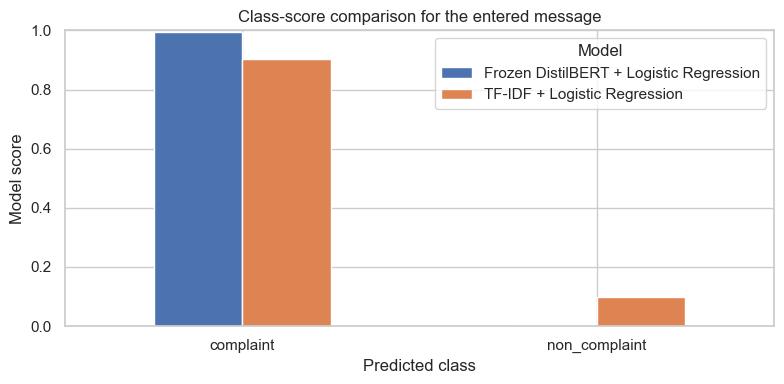

,Passenger message,Estimated issue type
0,My train is delayed by four hours and nobody is announcing the reason.,punctuality


Interpretation: the two complaint detectors may agree or disagree. Prediction time here measures one-message inference in this run; it is not the total model-training time.
Note: These are model predictions for demonstration, not official railway decisions.


In [23]:
# Live comparison: best-performing model vs fast baseline
passenger_message = input("Enter a railway passenger message: ")

if passenger_message.strip():
    cleaned_message = clean_text(passenger_message)

    # 1. Frozen DistilBERT embeddings + Logistic Regression (best macro-F1 in evaluation)
    start = time.perf_counter()
    bert_message_embedding = get_bert_embeddings([cleaned_message])
    bert_label = bert_classifier.predict(bert_message_embedding)[0]
    bert_seconds = time.perf_counter() - start

    # 2. TF-IDF + Logistic Regression (lightweight, fast baseline)
    start = time.perf_counter()
    tfidf_label = tfidf_model.predict([cleaned_message])[0]
    tfidf_seconds = time.perf_counter() - start

    comparison_table = pd.DataFrame({
        "Model": [
            "Frozen DistilBERT embeddings + Logistic Regression",
            "TF-IDF + Logistic Regression"
        ],
        "Predicted label": [bert_label, tfidf_label],
        "Prediction time (seconds)": [bert_seconds, tfidf_seconds],
        "Role in demonstration": ["Best reported Macro-F1", "Fast baseline"]
    })
    display(comparison_table.style.format({"Prediction time (seconds)": "{:.4f}"}).set_caption(
        "Model predictions for the same passenger message"
    ))

    # Compare model scores, if both classifiers support probability estimates.
    score_rows = []
    if hasattr(bert_classifier, "predict_proba"):
        bert_scores = bert_classifier.predict_proba(bert_message_embedding)[0]
        for label, score in zip(bert_classifier.classes_, bert_scores):
            score_rows.append({
                "Model": "Frozen DistilBERT + Logistic Regression",
                "Label": label,
                "Model score": score
            })
    if hasattr(tfidf_model, "predict_proba"):
        tfidf_scores = tfidf_model.predict_proba([cleaned_message])[0]
        tfidf_classes = tfidf_model.named_steps["classifier"].classes_
        for label, score in zip(tfidf_classes, tfidf_scores):
            score_rows.append({
                "Model": "TF-IDF + Logistic Regression",
                "Label": label,
                "Model score": score
            })

    if score_rows:
        score_table = pd.DataFrame(score_rows)
        display(score_table.style.format({"Model score": "{:.1%}"}).set_caption(
            "Predicted class scores (not a guarantee of correctness)"
        ))
        score_pivot = score_table.pivot(index="Label", columns="Model", values="Model score")
        ax = score_pivot.plot(kind="bar", figsize=(8, 4), ylim=(0, 1))
        ax.set_title("Class-score comparison for the entered message")
        ax.set_ylabel("Model score")
        ax.set_xlabel("Predicted class")
        plt.xticks(rotation=0)
        plt.tight_layout()
        plt.show()

    # Issue-type model remains a separate task from complaint/non-complaint detection.
    issue_prediction = type_model.predict([cleaned_message])[0]
    display(pd.DataFrame({
        "Passenger message": [passenger_message],
        "Estimated issue type": [issue_prediction]
    }).style.set_caption("Issue-type estimate"))

    print("Interpretation: the two complaint detectors may agree or disagree. "
          "Prediction time here measures one-message inference in this run; "
          "it is not the total model-training time.")
    print("Note: These are model predictions for demonstration, not official railway decisions.")
else:
    print("Please enter a message before running the cell.")

### 2. Food quality — complaint

Enter a railway passenger message:  The food served on the train was cold, overpriced and unhygienic.


,Model,Predicted label,Prediction time (seconds),Role in demonstration
0,Frozen DistilBERT embeddings + Logistic Regression,complaint,0.0646,Best reported Macro-F1
1,TF-IDF + Logistic Regression,complaint,0.0013,Fast baseline


,Model,Label,Model score
0,Frozen DistilBERT + Logistic Regression,complaint,94.7%
1,Frozen DistilBERT + Logistic Regression,non_complaint,5.3%
2,TF-IDF + Logistic Regression,complaint,52.1%
3,TF-IDF + Logistic Regression,non_complaint,47.9%


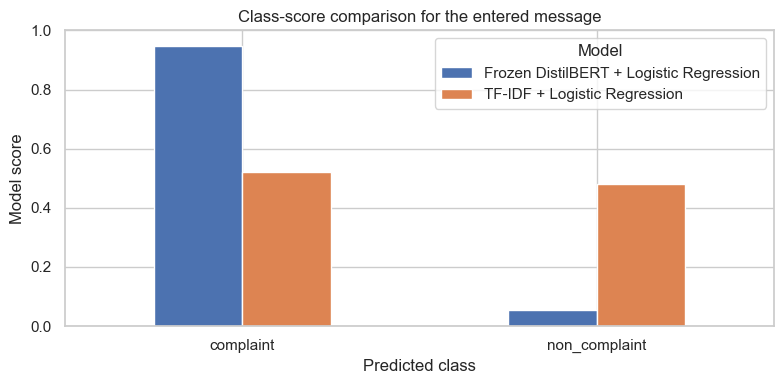

,Passenger message,Estimated issue type
0,"The food served on the train was cold, overpriced and unhygienic.",catering & vending service


Interpretation: the two complaint detectors may agree or disagree. Prediction time here measures one-message inference in this run; it is not the total model-training time.
Note: These are model predictions for demonstration, not official railway decisions.


In [24]:
# Live comparison: best-performing model vs fast baseline
passenger_message = input("Enter a railway passenger message: ")

if passenger_message.strip():
    cleaned_message = clean_text(passenger_message)

    # 1. Frozen DistilBERT embeddings + Logistic Regression (best macro-F1 in evaluation)
    start = time.perf_counter()
    bert_message_embedding = get_bert_embeddings([cleaned_message])
    bert_label = bert_classifier.predict(bert_message_embedding)[0]
    bert_seconds = time.perf_counter() - start

    # 2. TF-IDF + Logistic Regression (lightweight, fast baseline)
    start = time.perf_counter()
    tfidf_label = tfidf_model.predict([cleaned_message])[0]
    tfidf_seconds = time.perf_counter() - start

    comparison_table = pd.DataFrame({
        "Model": [
            "Frozen DistilBERT embeddings + Logistic Regression",
            "TF-IDF + Logistic Regression"
        ],
        "Predicted label": [bert_label, tfidf_label],
        "Prediction time (seconds)": [bert_seconds, tfidf_seconds],
        "Role in demonstration": ["Best reported Macro-F1", "Fast baseline"]
    })
    display(comparison_table.style.format({"Prediction time (seconds)": "{:.4f}"}).set_caption(
        "Model predictions for the same passenger message"
    ))

    # Compare model scores, if both classifiers support probability estimates.
    score_rows = []
    if hasattr(bert_classifier, "predict_proba"):
        bert_scores = bert_classifier.predict_proba(bert_message_embedding)[0]
        for label, score in zip(bert_classifier.classes_, bert_scores):
            score_rows.append({
                "Model": "Frozen DistilBERT + Logistic Regression",
                "Label": label,
                "Model score": score
            })
    if hasattr(tfidf_model, "predict_proba"):
        tfidf_scores = tfidf_model.predict_proba([cleaned_message])[0]
        tfidf_classes = tfidf_model.named_steps["classifier"].classes_
        for label, score in zip(tfidf_classes, tfidf_scores):
            score_rows.append({
                "Model": "TF-IDF + Logistic Regression",
                "Label": label,
                "Model score": score
            })

    if score_rows:
        score_table = pd.DataFrame(score_rows)
        display(score_table.style.format({"Model score": "{:.1%}"}).set_caption(
            "Predicted class scores (not a guarantee of correctness)"
        ))
        score_pivot = score_table.pivot(index="Label", columns="Model", values="Model score")
        ax = score_pivot.plot(kind="bar", figsize=(8, 4), ylim=(0, 1))
        ax.set_title("Class-score comparison for the entered message")
        ax.set_ylabel("Model score")
        ax.set_xlabel("Predicted class")
        plt.xticks(rotation=0)
        plt.tight_layout()
        plt.show()

    # Issue-type model remains a separate task from complaint/non-complaint detection.
    issue_prediction = type_model.predict([cleaned_message])[0]
    display(pd.DataFrame({
        "Passenger message": [passenger_message],
        "Estimated issue type": [issue_prediction]
    }).style.set_caption("Issue-type estimate"))

    print("Interpretation: the two complaint detectors may agree or disagree. "
          "Prediction time here measures one-message inference in this run; "
          "it is not the total model-training time.")
    print("Note: These are model predictions for demonstration, not official railway decisions.")
else:
    print("Please enter a message before running the cell.")

### 3. Positive feedback — non-complaint

Enter a railway passenger message:  The train was clean, the staff were helpful, and I had a pleasant journey.


,Model,Predicted label,Prediction time (seconds),Role in demonstration
0,Frozen DistilBERT embeddings + Logistic Regression,non_complaint,0.0557,Best reported Macro-F1
1,TF-IDF + Logistic Regression,non_complaint,0.0013,Fast baseline


,Model,Label,Model score
0,Frozen DistilBERT + Logistic Regression,complaint,0.0%
1,Frozen DistilBERT + Logistic Regression,non_complaint,100.0%
2,TF-IDF + Logistic Regression,complaint,48.4%
3,TF-IDF + Logistic Regression,non_complaint,51.6%


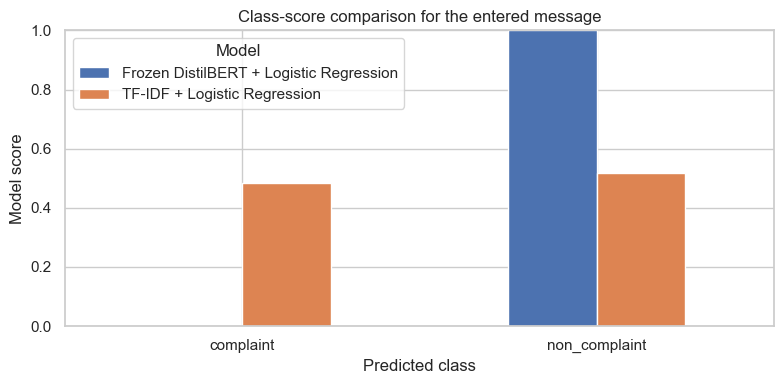

,Passenger message,Estimated issue type
0,"The train was clean, the staff were helpful, and I had a pleasant journey.",cleanliness


Interpretation: the two complaint detectors may agree or disagree. Prediction time here measures one-message inference in this run; it is not the total model-training time.
Note: These are model predictions for demonstration, not official railway decisions.


In [25]:
# Live comparison: best-performing model vs fast baseline
passenger_message = input("Enter a railway passenger message: ")

if passenger_message.strip():
    cleaned_message = clean_text(passenger_message)

    # 1. Frozen DistilBERT embeddings + Logistic Regression (best macro-F1 in evaluation)
    start = time.perf_counter()
    bert_message_embedding = get_bert_embeddings([cleaned_message])
    bert_label = bert_classifier.predict(bert_message_embedding)[0]
    bert_seconds = time.perf_counter() - start

    # 2. TF-IDF + Logistic Regression (lightweight, fast baseline)
    start = time.perf_counter()
    tfidf_label = tfidf_model.predict([cleaned_message])[0]
    tfidf_seconds = time.perf_counter() - start

    comparison_table = pd.DataFrame({
        "Model": [
            "Frozen DistilBERT embeddings + Logistic Regression",
            "TF-IDF + Logistic Regression"
        ],
        "Predicted label": [bert_label, tfidf_label],
        "Prediction time (seconds)": [bert_seconds, tfidf_seconds],
        "Role in demonstration": ["Best reported Macro-F1", "Fast baseline"]
    })
    display(comparison_table.style.format({"Prediction time (seconds)": "{:.4f}"}).set_caption(
        "Model predictions for the same passenger message"
    ))

    # Compare model scores, if both classifiers support probability estimates.
    score_rows = []
    if hasattr(bert_classifier, "predict_proba"):
        bert_scores = bert_classifier.predict_proba(bert_message_embedding)[0]
        for label, score in zip(bert_classifier.classes_, bert_scores):
            score_rows.append({
                "Model": "Frozen DistilBERT + Logistic Regression",
                "Label": label,
                "Model score": score
            })
    if hasattr(tfidf_model, "predict_proba"):
        tfidf_scores = tfidf_model.predict_proba([cleaned_message])[0]
        tfidf_classes = tfidf_model.named_steps["classifier"].classes_
        for label, score in zip(tfidf_classes, tfidf_scores):
            score_rows.append({
                "Model": "TF-IDF + Logistic Regression",
                "Label": label,
                "Model score": score
            })

    if score_rows:
        score_table = pd.DataFrame(score_rows)
        display(score_table.style.format({"Model score": "{:.1%}"}).set_caption(
            "Predicted class scores (not a guarantee of correctness)"
        ))
        score_pivot = score_table.pivot(index="Label", columns="Model", values="Model score")
        ax = score_pivot.plot(kind="bar", figsize=(8, 4), ylim=(0, 1))
        ax.set_title("Class-score comparison for the entered message")
        ax.set_ylabel("Model score")
        ax.set_xlabel("Predicted class")
        plt.xticks(rotation=0)
        plt.tight_layout()
        plt.show()

    # Issue-type model remains a separate task from complaint/non-complaint detection.
    issue_prediction = type_model.predict([cleaned_message])[0]
    display(pd.DataFrame({
        "Passenger message": [passenger_message],
        "Estimated issue type": [issue_prediction]
    }).style.set_caption("Issue-type estimate"))

    print("Interpretation: the two complaint detectors may agree or disagree. "
          "Prediction time here measures one-message inference in this run; "
          "it is not the total model-training time.")
    print("Note: These are model predictions for demonstration, not official railway decisions.")
else:
    print("Please enter a message before running the cell.")


### 4. Neutral enquiry

Enter a railway passenger message:  Can someone tell me the expected arrival time of the train?


,Model,Predicted label,Prediction time (seconds),Role in demonstration
0,Frozen DistilBERT embeddings + Logistic Regression,non_complaint,0.0499,Best reported Macro-F1
1,TF-IDF + Logistic Regression,complaint,0.0012,Fast baseline


,Model,Label,Model score
0,Frozen DistilBERT + Logistic Regression,complaint,45.3%
1,Frozen DistilBERT + Logistic Regression,non_complaint,54.7%
2,TF-IDF + Logistic Regression,complaint,65.6%
3,TF-IDF + Logistic Regression,non_complaint,34.4%


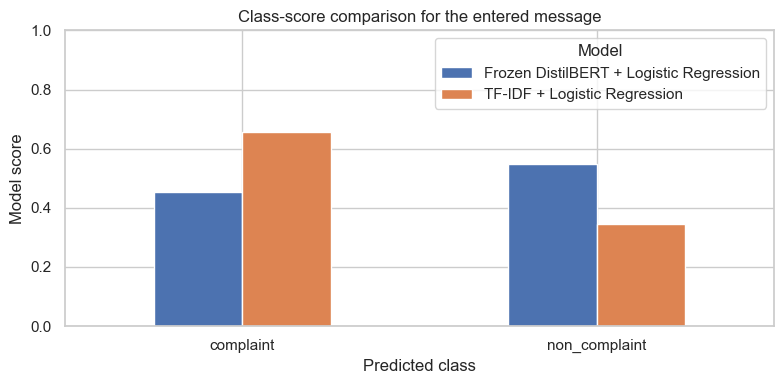

,Passenger message,Estimated issue type
0,Can someone tell me the expected arrival time of the train?,punctuality


Interpretation: the two complaint detectors may agree or disagree. Prediction time here measures one-message inference in this run; it is not the total model-training time.
Note: These are model predictions for demonstration, not official railway decisions.


In [26]:
# Live comparison: best-performing model vs fast baseline
passenger_message = input("Enter a railway passenger message: ")

if passenger_message.strip():
    cleaned_message = clean_text(passenger_message)

    # 1. Frozen DistilBERT embeddings + Logistic Regression (best macro-F1 in evaluation)
    start = time.perf_counter()
    bert_message_embedding = get_bert_embeddings([cleaned_message])
    bert_label = bert_classifier.predict(bert_message_embedding)[0]
    bert_seconds = time.perf_counter() - start

    # 2. TF-IDF + Logistic Regression (lightweight, fast baseline)
    start = time.perf_counter()
    tfidf_label = tfidf_model.predict([cleaned_message])[0]
    tfidf_seconds = time.perf_counter() - start

    comparison_table = pd.DataFrame({
        "Model": [
            "Frozen DistilBERT embeddings + Logistic Regression",
            "TF-IDF + Logistic Regression"
        ],
        "Predicted label": [bert_label, tfidf_label],
        "Prediction time (seconds)": [bert_seconds, tfidf_seconds],
        "Role in demonstration": ["Best reported Macro-F1", "Fast baseline"]
    })
    display(comparison_table.style.format({"Prediction time (seconds)": "{:.4f}"}).set_caption(
        "Model predictions for the same passenger message"
    ))

    # Compare model scores, if both classifiers support probability estimates.
    score_rows = []
    if hasattr(bert_classifier, "predict_proba"):
        bert_scores = bert_classifier.predict_proba(bert_message_embedding)[0]
        for label, score in zip(bert_classifier.classes_, bert_scores):
            score_rows.append({
                "Model": "Frozen DistilBERT + Logistic Regression",
                "Label": label,
                "Model score": score
            })
    if hasattr(tfidf_model, "predict_proba"):
        tfidf_scores = tfidf_model.predict_proba([cleaned_message])[0]
        tfidf_classes = tfidf_model.named_steps["classifier"].classes_
        for label, score in zip(tfidf_classes, tfidf_scores):
            score_rows.append({
                "Model": "TF-IDF + Logistic Regression",
                "Label": label,
                "Model score": score
            })

    if score_rows:
        score_table = pd.DataFrame(score_rows)
        display(score_table.style.format({"Model score": "{:.1%}"}).set_caption(
            "Predicted class scores (not a guarantee of correctness)"
        ))
        score_pivot = score_table.pivot(index="Label", columns="Model", values="Model score")
        ax = score_pivot.plot(kind="bar", figsize=(8, 4), ylim=(0, 1))
        ax.set_title("Class-score comparison for the entered message")
        ax.set_ylabel("Model score")
        ax.set_xlabel("Predicted class")
        plt.xticks(rotation=0)
        plt.tight_layout()
        plt.show()

    # Issue-type model remains a separate task from complaint/non-complaint detection.
    issue_prediction = type_model.predict([cleaned_message])[0]
    display(pd.DataFrame({
        "Passenger message": [passenger_message],
        "Estimated issue type": [issue_prediction]
    }).style.set_caption("Issue-type estimate"))

    print("Interpretation: the two complaint detectors may agree or disagree. "
          "Prediction time here measures one-message inference in this run; "
          "it is not the total model-training time.")
    print("Note: These are model predictions for demonstration, not official railway decisions.")
else:
    print("Please enter a message before running the cell.")


### 5. Informal Hinglish

Enter a railway passenger message:  Train bahut late hai aur station par koi proper information nahi mil rahi.


,Model,Predicted label,Prediction time (seconds),Role in demonstration
0,Frozen DistilBERT embeddings + Logistic Regression,complaint,0.0554,Best reported Macro-F1
1,TF-IDF + Logistic Regression,complaint,0.0015,Fast baseline


,Model,Label,Model score
0,Frozen DistilBERT + Logistic Regression,complaint,99.0%
1,Frozen DistilBERT + Logistic Regression,non_complaint,1.0%
2,TF-IDF + Logistic Regression,complaint,69.2%
3,TF-IDF + Logistic Regression,non_complaint,30.8%


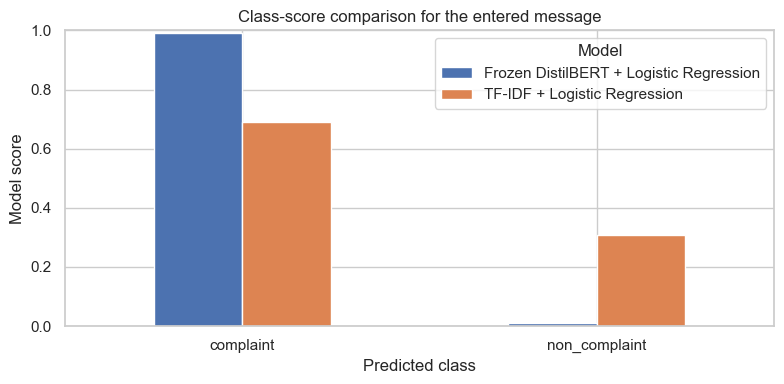

,Passenger message,Estimated issue type
0,Train bahut late hai aur station par koi proper information nahi mil rahi.,punctuality


Interpretation: the two complaint detectors may agree or disagree. Prediction time here measures one-message inference in this run; it is not the total model-training time.
Note: These are model predictions for demonstration, not official railway decisions.


In [27]:
# Live comparison: best-performing model vs fast baseline
passenger_message = input("Enter a railway passenger message: ")

if passenger_message.strip():
    cleaned_message = clean_text(passenger_message)

    # 1. Frozen DistilBERT embeddings + Logistic Regression (best macro-F1 in evaluation)
    start = time.perf_counter()
    bert_message_embedding = get_bert_embeddings([cleaned_message])
    bert_label = bert_classifier.predict(bert_message_embedding)[0]
    bert_seconds = time.perf_counter() - start

    # 2. TF-IDF + Logistic Regression (lightweight, fast baseline)
    start = time.perf_counter()
    tfidf_label = tfidf_model.predict([cleaned_message])[0]
    tfidf_seconds = time.perf_counter() - start

    comparison_table = pd.DataFrame({
        "Model": [
            "Frozen DistilBERT embeddings + Logistic Regression",
            "TF-IDF + Logistic Regression"
        ],
        "Predicted label": [bert_label, tfidf_label],
        "Prediction time (seconds)": [bert_seconds, tfidf_seconds],
        "Role in demonstration": ["Best reported Macro-F1", "Fast baseline"]
    })
    display(comparison_table.style.format({"Prediction time (seconds)": "{:.4f}"}).set_caption(
        "Model predictions for the same passenger message"
    ))

    # Compare model scores, if both classifiers support probability estimates.
    score_rows = []
    if hasattr(bert_classifier, "predict_proba"):
        bert_scores = bert_classifier.predict_proba(bert_message_embedding)[0]
        for label, score in zip(bert_classifier.classes_, bert_scores):
            score_rows.append({
                "Model": "Frozen DistilBERT + Logistic Regression",
                "Label": label,
                "Model score": score
            })
    if hasattr(tfidf_model, "predict_proba"):
        tfidf_scores = tfidf_model.predict_proba([cleaned_message])[0]
        tfidf_classes = tfidf_model.named_steps["classifier"].classes_
        for label, score in zip(tfidf_classes, tfidf_scores):
            score_rows.append({
                "Model": "TF-IDF + Logistic Regression",
                "Label": label,
                "Model score": score
            })

    if score_rows:
        score_table = pd.DataFrame(score_rows)
        display(score_table.style.format({"Model score": "{:.1%}"}).set_caption(
            "Predicted class scores (not a guarantee of correctness)"
        ))
        score_pivot = score_table.pivot(index="Label", columns="Model", values="Model score")
        ax = score_pivot.plot(kind="bar", figsize=(8, 4), ylim=(0, 1))
        ax.set_title("Class-score comparison for the entered message")
        ax.set_ylabel("Model score")
        ax.set_xlabel("Predicted class")
        plt.xticks(rotation=0)
        plt.tight_layout()
        plt.show()

    # Issue-type model remains a separate task from complaint/non-complaint detection.
    issue_prediction = type_model.predict([cleaned_message])[0]
    display(pd.DataFrame({
        "Passenger message": [passenger_message],
        "Estimated issue type": [issue_prediction]
    }).style.set_caption("Issue-type estimate"))

    print("Interpretation: the two complaint detectors may agree or disagree. "
          "Prediction time here measures one-message inference in this run; "
          "it is not the total model-training time.")
    print("Note: These are model predictions for demonstration, not official railway decisions.")
else:
    print("Please enter a message before running the cell.")


---

In [28]:
print("TF-IDF model:", "tfidf_model" in globals())
print("Issue classifier:", "issue_model" in globals())

TF-IDF model: True
Issue classifier: False


In [30]:
models_to_check = [
    "tfidf_model",
    "word2vec_model",
    "glove_model",
    "lstm_model",
    "bert_classifier",
    "type_model"
]

for model_name in models_to_check:
    print(f"{model_name}: {'Available' if model_name in globals() else 'Not available'}")

tfidf_model: Available
word2vec_model: Available
glove_model: Available
lstm_model: Available
bert_classifier: Available
type_model: Available


In [32]:
from pathlib import Path

models_dir = Path("models")
models_dir.mkdir(exist_ok=True)

with open(models_dir / "tokenizer.json", "w", encoding="utf-8") as f:
    f.write(tokenizer.to_json())

bert_tokenizer.save_pretrained(models_dir / "distilbert")
bert_encoder.save_pretrained(models_dir / "distilbert")

print("Tokenizer and DistilBERT files saved!")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Tokenizer and DistilBERT files saved!


In [33]:
import os

print("Notebook working folder:", os.getcwd())
print("\nFiles in the models folder:")

for root, dirs, files in os.walk(os.getcwd()):
    dirs[:] = [d for d in dirs if d not in [".venv", "venv", "__pycache__"]]
    for file in files:
        if file.endswith((".pkl", ".joblib", ".model", ".keras", ".kv")):
            print(os.path.join(root, file))

Notebook working folder: C:\Users\Manjiri Apshinge\Downloads\RailSahayak_AI_App

Files in the models folder:
C:\Users\Manjiri Apshinge\Downloads\RailSahayak_AI_App\models\bert_classifier.pkl
C:\Users\Manjiri Apshinge\Downloads\RailSahayak_AI_App\models\glove_classifier.pkl
C:\Users\Manjiri Apshinge\Downloads\RailSahayak_AI_App\models\glove_twitter_25.kv
C:\Users\Manjiri Apshinge\Downloads\RailSahayak_AI_App\models\label_encoder.pkl
C:\Users\Manjiri Apshinge\Downloads\RailSahayak_AI_App\models\lstm_model.keras
C:\Users\Manjiri Apshinge\Downloads\RailSahayak_AI_App\models\tfidf_model.pkl
C:\Users\Manjiri Apshinge\Downloads\RailSahayak_AI_App\models\type_model.pkl
C:\Users\Manjiri Apshinge\Downloads\RailSahayak_AI_App\models\w2v_classifier.pkl
C:\Users\Manjiri Apshinge\Downloads\RailSahayak_AI_App\models\word2vec.model


<h1 align="center">Workflow summary</h1>

```text
Passenger tweets → Text cleaning → Train/test split
        ↓
BoW / TF-IDF / Word2Vec / GloVe / DistilBERT
        ↓
Complaint classification → Model comparison → Error analysis
        ↓
Issue-type classification and LDA topic exploration
        ↓
Test a new passenger message
```


---

<h1 align="center">References</h1>


1. Hugging Face. (n.d.). *Indian Railways Complaint Tweets Dataset*. https://huggingface.co/datasets/faizmubeen/indian_railways_complaint_tweets

2. Hugging Face. (n.d.). *DistilBERT Documentation*. https://huggingface.co/docs/transformers/model_doc/distilbert

3. Scikit-learn Developers. (n.d.). *TfidfVectorizer Documentation*. https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html

4. Scikit-learn Developers. (n.d.). *LogisticRegression Documentation*. https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html

5. Scikit-learn Developers. (n.d.). *Model Evaluation Documentation*. https://scikit-learn.org/stable/modules/model_evaluation.html

6. Mikolov, T., Chen, K., Corrado, G., & Dean, J. (2013). *Efficient Estimation of Word Representations in Vector Space*. https://arxiv.org/abs/1301.3781

7. Hochreiter, S., & Schmidhuber, J. (1997). *Long Short-Term Memory*. Neural Computation, 9(8), 1735–1780. https://doi.org/10.1162/neco.1997.9.8.1735

8. Gensim. (n.d.). *Latent Dirichlet Allocation (LDA) Model Documentation*. https://radimrehurek.com/gensim/models/ldamodel.html

<h1 align="center">xxx</h1>